# MSH chain on a 2D substrate: dense and sparse Python reference

Reference for `msh_substrate_tn.ipynb`: the same model as a sparse matrix (SciPy), with dense diagonalization where it fits and sparse
methods beyond. See the tensor-network notebook for the goal and the model.

**Contents**
1. Hamiltonian
2. Check against the tensor-network Hamiltonian
3. Lowest levels against substrate width
4. Sparse matrix size against system size
5. Zero-mode benchmark: dense and sparse
6. MUMPS estimates beyond the benchmark
7. Charge difference: mask method and single-mode formula
8. A substrate the zero modes leak into: parameter scan and MUMPS reference

**Conventions.** Site index $n = i_x + i_y N_x$ (as in the Julia notebook), matrix index $4n + c$ with kwant's spinor
$(c_\uparrow, c_\downarrow, c^\dagger_\downarrow, -c^\dagger_\uparrow)$, so the BdG Hamiltonian reads
$\tau_z(\epsilon - \mu) + \Delta\tau_x + J\,\mathbf S\cdot\boldsymbol\sigma$ on site, with Rashba hoppings $h_x = -t\tau_z + i\alpha\tau_z\sigma_y$,
$h_y = -t\tau_z - i\alpha\tau_z\sigma_x$ ($H_{r+d,\,r} = h_d$).

In [1]:
import os, time, resource, queue
import multiprocessing as mp
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[v] = "1"        # single thread (set before NumPy is imported), as in the Julia notebook
import numpy as np
import scipy.linalg as la
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh, splu, LinearOperator
import mumps                 # python-mumps (MUMPS 5.8, sequential), conda-forge

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

s0 = np.eye(2); sx = np.array([[0, 1], [1, 0]]); sy = np.array([[0, -1j], [1j, 0]]); sz = np.diag([1.0, -1.0])
tzs0, txs0 = np.kron(sz, s0), np.kron(sx, s0)
t0sx, t0sy, t0sz = np.kron(s0, sx), np.kron(s0, sy), np.kron(s0, sz)
tzsx, tzsy = np.kron(sz, sx), np.kron(sz, sy)

S_z = lambda ix: (0.0, 0.0, 1.0)
S_tilt = lambda ix: (np.sin(0.3*ix)*np.cos(0.7), np.sin(0.3*ix)*np.sin(0.7), np.cos(0.3*ix))

# Every calculation that builds a large matrix runs in a forked process (in_fresh_process), so that this kernel stays small:
# a forked process starts with the kernel's resident memory, which would otherwise inflate its measured peak memory.
def in_fresh_process(fn, *args):
    "Run fn(*args) in a forked process. Returns (result or None, peak resident memory in MB, status)."
    ctx = mp.get_context("fork"); q = ctx.Queue()
    def target():
        try:
            out, status = fn(*args), "ok"
        except BaseException as e:
            out, status = None, f"{type(e).__name__}: {e}".replace(",", ";").strip()
        q.put((out, resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, status))
    p = ctx.Process(target=target); p.start()
    while True:                                          # wait for the result, but notice a process that dies (e.g. killed)
        try:
            res = q.get(timeout=5); break
        except queue.Empty:
            if not p.is_alive():
                res = (None, float("nan"), f"process died (exit code {p.exitcode})"); break
    p.join()
    return res

## 1. Hamiltonian

`ham(Lx, Ly, ell, S)` builds the sparse BdG matrix from Kronecker products: with $n = i_y N_x + i_x$, a site operator is
`kron(A_y, B_x)`, and the full matrix is `kron(site operator, 4×4 spinor matrix)`. The x bonds are `kron(I_y, shift_x)` (open, so
no wrap between rows), the y bonds `kron(shift_y, I_x)`. The exchange is `kron(diag(J S_k), σ_k)` on the chain sites.

In [2]:
def shift(n):
    "n × n matrix with ones at (i + 1, i): |i⟩ → |i + 1⟩, open boundary"
    return sp.diags(np.ones(n - 1), -1, shape=(n, n), format="csr")

def chain_sites(Lx, Ly, ell):
    Nx, Ny = 2**Lx, 2**Ly
    x0, iy0 = (Nx - ell) // 2, Ny // 2
    return np.arange(x0, x0 + ell), iy0

def ham(Lx, Ly, ell, S=S_z, t=1.0, mu=-7.0, alpha=0.9, Delta=2.4, J=5.8):
    "Sparse 4N × 4N BdG Hamiltonian (CSR) of the MSH chain on the 2^Lx × 2^Ly substrate."
    Nx, Ny = 2**Lx, 2**Ly; N = Nx * Ny
    Ix, Iy = sp.identity(Nx, format="csr"), sp.identity(Ny, format="csr")
    hx = -t * tzs0 + 1j * alpha * tzsy
    hy = -t * tzs0 - 1j * alpha * tzsx
    Tx = sp.kron(sp.kron(Iy, shift(Nx)), hx)
    Ty = sp.kron(sp.kron(shift(Ny), Ix), hy)
    H = sp.kron(sp.identity(N), -mu * tzs0 + Delta * txs0) + Tx + Tx.conj().T + Ty + Ty.conj().T
    xs, iy0 = chain_sites(Lx, Ly, ell)
    for k, sk in enumerate((t0sx, t0sy, t0sz)):
        v = np.zeros(N)
        v[xs + iy0 * Nx] = [J * S(ix)[k] for ix in xs]
        if np.abs(v).max() > 1e-14:
            H = H + sp.kron(sp.diags(v), sk)
    return H.tocsr()

## 2. Check against the tensor-network Hamiltonian

`data/tn_check_H.npz` holds the dense MPO matrices of `msh_substrate_tn.ipynb` (section 4), with Julia's index $n_b\cdot2N + \sigma N + n$
and spinor $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$. The change of basis to $4n + c$ with
$(c_\uparrow, c_\downarrow, c^\dagger_\downarrow, -c^\dagger_\uparrow)$ is a signed permutation $W$; the check is
$\max|W H_{\rm TN} W^T - H_{\rm py}|$ element by element.

In [3]:
def julia_to_python(Hj, N):
    "Julia basis (index nb·2N + σ·N + n) → Python basis (index 4n + c)."
    W = sp.lil_matrix((4 * N, 4 * N))
    for n in range(N):
        W[4*n + 0, 0*N + n] = 1            # c↑   ← (nb = 0, σ = ↑)
        W[4*n + 1, 1*N + n] = 1            # c↓   ← (nb = 0, σ = ↓)
        W[4*n + 2, 2*N + 1*N + n] = 1      # c†↓  ← (nb = 1, σ = ↓)
        W[4*n + 3, 2*N + 0*N + n] = -1     # −c†↑ ← (nb = 1, σ = ↑)
    W = W.tocsr()
    return W @ Hj @ W.T

tn_check = np.load(os.path.join(DATA_DIR, "tn_check_H.npz"))
worst = 0.0
for key in sorted(tn_check.files):
    _, Lx, Ly, ell, name = key.split("_"); Lx, Ly, ell = int(Lx), int(Ly), int(ell)
    Hp = ham(Lx, Ly, ell, S_z if name == "z" else S_tilt).toarray()
    err = np.abs(julia_to_python(tn_check[key], 2**(Lx + Ly)) - Hp).max(); worst = max(worst, err)
    print(f"Lx = {Lx}, Ly = {Ly}, ℓ = {ell:2d}, {name:<4s}: D = {Hp.shape[0]:3d}, max|H_TN − H_py| = {err:.1e}")
print(f"largest difference: {worst:.1e}")
assert worst < 1e-10

Lx = 2, Ly = 3, ℓ =  3, tilt: D = 128, max|H_TN − H_py| = 2.6e-14
Lx = 2, Ly = 3, ℓ =  3, z   : D = 128, max|H_TN − H_py| = 2.8e-14
Lx = 3, Ly = 0, ℓ =  6, tilt: D =  32, max|H_TN − H_py| = 4.7e-14
Lx = 3, Ly = 0, ℓ =  6, z   : D =  32, max|H_TN − H_py| = 3.0e-14
Lx = 3, Ly = 1, ℓ =  6, tilt: D =  64, max|H_TN − H_py| = 2.5e-14
Lx = 3, Ly = 1, ℓ =  6, z   : D =  64, max|H_TN − H_py| = 4.9e-14
Lx = 3, Ly = 2, ℓ =  5, tilt: D = 128, max|H_TN − H_py| = 7.0e-14
Lx = 3, Ly = 2, ℓ =  5, z   : D = 128, max|H_TN − H_py| = 6.2e-14
Lx = 4, Ly = 2, ℓ = 10, tilt: D = 256, max|H_TN − H_py| = 9.8e-14
Lx = 4, Ly = 2, ℓ = 10, z   : D = 256, max|H_TN − H_py| = 4.5e-14
largest difference: 9.8e-14


## 3. Lowest levels against substrate width

$L_x = 6$ (64 columns), chain $\ell = 48$, all spins along $\hat z$; the four smallest $|E|$ from shift-invert `eigsh` ($\sigma = 0$).
The first pair is the Majorana pair; the next level is the bulk gap. $L_y = 0$ is the 1D chain. Because the substrate at $\mu = -7$ is
gapped, the gap converges after a few rows: from there on, growing the substrate changes the cost but not the physics, which makes
the converged values a correctness check at sizes where dense diagonalization is no longer possible.

In [4]:
print(f"{'Ly':>3s} {'rows':>5s} {'D':>7s} {'|E| pair':>10s} {'gap':>8s} {'eigsh':>8s}")
for Ly in range(7):
    H = ham(6, Ly, 48)
    t_ = time.perf_counter()
    E = np.sort(np.abs(eigsh(H, k=6, sigma=0, which="LM", return_eigenvectors=False)))
    print(f"{Ly:3d} {2**Ly:5d} {H.shape[0]:7d} {E[0]:10.2e} {E[2]:8.4f} {time.perf_counter() - t_:7.2f}s")

 Ly  rows       D   |E| pair      gap    eigsh
  0     1     256   2.60e-11   0.2563    0.00s
  1     2     512   5.10e-15   0.4283    0.01s
  2     4    1024   6.74e-14   0.5613    0.07s
  3     8    2048   3.40e-14   0.5491    0.13s
  4    16    4096   3.39e-14   0.5491    0.35s
  5    32    8192   3.39e-14   0.5491    1.32s
  6    64   16384   3.39e-14   0.5491    3.98s


## 4. Sparse matrix size against system size

The width and square scans of section 5 of the tensor-network notebook: number of nonzeros of the sparse BdG matrix, its CSR memory
and the build time. The MPO memory (stored elements of its tensors) is listed there for comparison.

In [5]:
scan = [(6, Ly, 48) for Ly in range(7)] + [(L, L, 3 * 2**L // 4) for L in range(4, 11)]
print(f"{'Lx':>3s} {'Ly':>3s} {'sites':>7s} {'D':>8s} {'nnz':>10s} {'CSR MB':>8s} {'build':>8s}")
def size_info(Lx, Ly, ell):
    t_ = time.perf_counter(); H = ham(Lx, Ly, ell); t_build = time.perf_counter() - t_
    return H.shape[0], H.nnz, (H.data.nbytes + H.indices.nbytes + H.indptr.nbytes) / 1e6, t_build

for Lx, Ly, ell in scan:
    (D, nnz, mb, t_build), _, _ = in_fresh_process(size_info, Lx, Ly, ell)     # large H only in a forked process
    print(f"{Lx:3d} {Ly:3d} {2**(Lx+Ly):7d} {D:8d} {nnz:10d} {mb:8.2f} {t_build:7.3f}s")

 Lx  Ly   sites        D        nnz   CSR MB    build
  6   0      64      256       3040     0.06   0.002s
  6   1     128      512       8128     0.16   0.002s
  6   2     256     1024      18304     0.37   0.002s
  6   3     512     2048      38656     0.78   0.002s
  6   4    1024     4096      79360     1.60   0.003s
  6   5    2048     8192     160768     3.25   0.005s
  6   6    4096    16384     323584     6.54   0.008s
  4   4     256     1024      19456     0.39   0.002s
  5   5    1024     4096      79872     1.61   0.003s
  6   6    4096    16384     323584     6.54   0.009s
  7   7   16384    65536    1302528    26.31   0.025s
  8   8   65536   262144    5226496   105.58   0.093s
  9   9  262144  1048576   20938752   422.97   0.373s
 10  10 1048576  4194304   83820544  1693.19   1.486s


## 5. Zero-mode benchmark: dense and sparse

The same sizes as section 7 of the tensor-network notebook ($\ell = 12$, spins along $\hat z$, up to $1024\times1024$ sites; the
tensor-network notebook also runs $2048\times2048$, for which section 6 gives the MUMPS estimates), single thread, three methods:

- **Dense** (while $D \le$ `DENSE_MAX_D` $= 16\,384$, i.e. up to $64\times64$ sites): `scipy.linalg.eigh` of the full matrix,
  restricted to the four eigenpairs in the middle of the spectrum (`subset_by_index`), which is what one does for the zero modes
  (about twice as fast as the full spectrum; the cost is the $O(D^3)$ reduction to tridiagonal form either way).
- **Sparse, two direct solvers.** Shift-invert Lanczos, `eigsh(H, k=4, sigma=0, OPinv=…)`, i.e. Lanczos on $H^{-1}$ with a sparse LU
  factorization of $H$; the time includes the factorization. Cost and memory are dominated by the fill-in of the $L$ and $U$ factors,
  which grows faster than $N$ on a 2D lattice, so the solver and its fill-reducing ordering matter:
  - `superlu`: SciPy's SuperLU, `splu(H, permc_spec="MMD_AT_PLUS_A")`. `eigsh` alone uses SuperLU's default column ordering
    (COLAMD); the matrix is structurally symmetric, and the symmetric minimum-degree ordering halves the fill and makes the solve
    2.3–2.5 times faster ($256\times256$: 21 s → 9 s; $512\times512$: 276 s → 110 s). At $1024\times1024$ sites ($D = 4\,194\,304$)
    SuperLU stops with *"Not enough memory to perform factorization"* within about a second under either ordering, with only a few GB
    in use on a machine with 188 GB: the factorization exceeds SuperLU's limits, not the machine's memory. That size is recorded as
    failed.
  - `mumps`: MUMPS 5.8 (sequential, `python-mumps`) with the nested-dissection ordering METIS, the standard choice for 2D meshes. Of
    the orderings MUMPS offers, METIS gave the smallest factorization at $256\times256$ (2.6 s, against 3.1 s for SCOTCH and 3.2 s for
    AMD). MUMPS stores its indices in 64 bits where it matters, so it factorizes $1024\times1024$.

**Memory.** Each (size, method) runs in a fresh process forked from this kernel (`in_fresh_process`, defined in the setup cell),
which reports its peak resident memory (`ru_maxrss`). The forked process starts with the kernel's resident memory, which is printed
once as the baseline (about 110 MB); every large matrix of this notebook is built in a forked process, so that the baseline stays the
same for all methods. The time
includes only the eigensolver (not building $H$). If the calculation raises an error or the process dies, the row is recorded with
`status` set to the error and NaN values.

From the four eigenpairs: $E_f$ (the $+E$ member of the pair), $\Delta Q = \langle\psi_f|\tau_z|\psi_f\rangle$ of its eigenvector, and
the gap (third smallest $|E|$). Each row is appended to `py_zero_modes.csv` as soon as it is done, and sizes already in that file are
skipped, so an interrupted run can be resumed (delete the file to start over). `RUN_ZM = False` only loads it.

In [6]:
RUN_ZM = True
DENSE_MAX_D = 16384
zm_file = "py_zero_modes.csv"
zm_scan = sorted([(6, Ly) for Ly in range(7)] + [(L, L) for L in (4, 5, 7, 8, 9, 10)], key=lambda p: (sum(p), p[1]))  # increasing N

def pair_values(E, V):
    "E_f, ΔQ of the +E member of the pair, and the gap, from a few eigenpairs around zero."
    o = np.argsort(np.abs(E)); ip = o[:2][np.argmax(E[o[:2]])]
    v = V[:, ip].reshape(-1, 4)
    return E[ip], np.sum(np.abs(v[:, :2])**2) - np.sum(np.abs(v[:, 2:])**2), np.abs(E[o[2]])

def solve(Lx, Ly, method, ell=12):
    "Zero modes of one system by one method: (time of the eigensolver, E_f, ΔQ, gap)."
    H = ham(Lx, Ly, ell); N = H.shape[0] // 4
    if method == "superlu":
        H = H.tocsc()
        t_ = time.perf_counter()
        try:
            lu = splu(H, permc_spec="MMD_AT_PLUS_A")
        except MemoryError:            # SuperLU prints its reason to stderr and raises an empty MemoryError
            raise MemoryError("SuperLU: not enough memory to perform factorization") from None
        E, V = eigsh(H, k=4, sigma=0, which="LM", OPinv=LinearOperator(H.shape, matvec=lu.solve, dtype=complex))
    elif method == "mumps":
        t_ = time.perf_counter()
        ctx = mumps.Context(); ctx.factor(H.tocoo(), ordering="metis")
        E, V = eigsh(H, k=4, sigma=0, which="LM", OPinv=LinearOperator(H.shape, matvec=ctx.solve, dtype=complex))
    else:
        H = H.toarray()
        t_ = time.perf_counter(); E, V = la.eigh(H, subset_by_index=[2*N - 2, 2*N + 1])
    return (time.perf_counter() - t_, *pair_values(E, V))

cols = ["Lx", "Ly", "ell", "N", "D", "method", "t", "rss_MB", "E_f", "dQ", "E_gap", "status"]
done = set()
if os.path.isfile(zm_file):
    old = np.genfromtxt(zm_file, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)
    done = {(int(r["Lx"]), int(r["Ly"]), r["method"]) for r in old}
if RUN_ZM:
    for m in ("superlu", "mumps", "dense"):                           # warm-up
        solve(4, 0, m)
    print(f"baseline peak memory of a forked process: {in_fresh_process(lambda: None)[1]:.0f} MB")
    if not done:
        with open(zm_file, "w") as f:
            f.write(",".join(cols) + "\n")
    for Lx, Ly in zm_scan:
        D = 4 * 2**(Lx + Ly)
        for method in ("superlu", "mumps", "dense") if D <= DENSE_MAX_D else ("superlu", "mumps"):
            if (Lx, Ly, method) in done:
                continue
            out, rss, status = in_fresh_process(solve, Lx, Ly, method)
            t, Ef, dQ, gap = out if out is not None else (np.nan,) * 4
            with open(zm_file, "a") as f:
                f.write(",".join(str(x) for x in (Lx, Ly, 12, D // 4, D, method, t, rss, Ef, dQ, gap, status)) + "\n")
            print(f"done Lx = {Lx}, Ly = {Ly}, {method}: {t:.2f} s, {rss:.0f} MB, {status}", flush=True)

zm = np.genfromtxt(zm_file, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)
zm = zm[np.lexsort((zm["method"], zm["N"]))]
print(f"{'Lx':>3s} {'Ly':>3s} {'N':>8s} {'D':>9s} {'method':>7s} {'time':>9s} {'RSS MB':>9s} {'E_f':>13s} {'ΔQ':>13s} {'gap':>7s}  status")
for r in zm:
    print(f"{r['Lx']:3d} {r['Ly']:3d} {r['N']:8d} {r['D']:9d} {r['method']:>7s} {r['t']:8.2f}s {r['rss_MB']:9.0f} {r['E_f']:13.6e} "
          f"{r['dQ']:+13.6e} {r['E_gap']:7.4f}  {r['status']}")

baseline peak memory of a forked process: 115 MB
 Lx  Ly        N         D  method      time    RSS MB           E_f            ΔQ     gap  status
  6   0       64       256   dense     0.01s       125  1.491239e-03 +4.159299e-02  0.3056  ok
  6   0       64       256   mumps     0.00s       120  1.491239e-03 +4.159299e-02  0.3056  ok
  6   0       64       256 superlu     0.00s       124  1.491239e-03 +4.159299e-02  0.3056  ok
  6   1      128       512   dense     0.03s       125  1.868688e-04 -2.135611e-03  0.4398  ok
  6   1      128       512   mumps     0.01s       120  1.868688e-04 -2.135611e-03  0.4398  ok
  6   1      128       512 superlu     0.00s       124  1.868688e-04 -2.135611e-03  0.4398  ok
  6   2      256      1024   dense     0.16s       145  4.146924e-04 -3.863993e-03  0.5639  ok
  4   4      256      1024   dense     0.18s       143  3.715561e-04 -3.441196e-03  0.5529  ok
  6   2      256      1024   mumps     0.02s       120  4.146924e-04 -3.863993e-03  0.5639  

## 6. MUMPS estimates beyond the benchmark

MUMPS's analysis step (ordering and symbolic factorization, no numerical work) predicts the size and cost of the factorization.
For the square scan up to $2048\times2048$ sites: the estimated number of nonzeros in the factors, the floating-point operations of
the factorization, and the in-core and out-of-core memory (MB). The in-core estimate is 7 % ($512\times512$) and 2.5 % ($1024\times1024$)
below the measured peak memory of section 5, so the $2048\times2048$ value (not run: it would need about 120 GB and, at the speed
measured at $1024\times1024$, roughly two hours) is a reliable estimate. Results go to `py_mumps_estimates.csv`.

In [7]:
RUN_EST = True
est_file = "py_mumps_estimates.csv"
est_cols = ["Lx", "Ly", "N", "D", "est_nonzeros", "est_flops", "est_mem_incore_MB", "est_mem_ooc_MB", "t_analysis"]

def mumps_estimate(L):
    H = ham(L, L, 12).tocoo()
    ctx = mumps.Context(); t_ = time.perf_counter(); ctx.analyze(H, ordering="metis"); t = time.perf_counter() - t_
    s = ctx.analysis_stats
    return (L, L, 4**L, 4 * 4**L, s.est_nonzeros, s.est_flops, s.est_mem_incore, s.est_mem_ooc, t)

if RUN_EST or not os.path.isfile(est_file):
    est = [in_fresh_process(mumps_estimate, L)[0] for L in range(7, 12)]
    with open(est_file, "w") as f:
        f.write(",".join(est_cols) + "\n")
        for r in est:
            f.write(",".join(str(x) for x in r) + "\n")
est = np.genfromtxt(est_file, delimiter=",", names=True)
print(f"{'substrate':>11s} {'N':>8s} {'nonzeros':>10s} {'flops':>10s} {'in-core MB':>11s} {'out-of-core MB':>15s}")
for r in est:
    print(f"{2**int(r['Lx']):>5d}×{2**int(r['Ly']):<5d} {int(r['N']):8d} {r['est_nonzeros']:10.2e} {r['est_flops']:10.2e} "
          f"{r['est_mem_incore_MB']:11.0f} {r['est_mem_ooc_MB']:15.0f}")

  substrate        N   nonzeros      flops  in-core MB  out-of-core MB
  128×128      16384   1.25e+07   2.89e+09         283              62
  256×256      65536   6.01e+07   2.52e+10        1326             236
  512×512     262144   2.83e+08   2.25e+11        6117             920
 1024×1024   1048576   1.31e+09   1.95e+12       27913            3711
 2048×2048   4194304   5.76e+09   1.54e+13      121184           14703


## 7. Charge difference: mask method and single-mode formula

Sections 5 and 6 (and the tensor-network notebook) compute the charge difference of the fermion mode from a single vector,
$\Delta Q = \langle\psi_f|\tau_z|\psi_f\rangle$. The CZ, QFT and period-finding notebooks, and section 7 of
`msh_chain_python_ed.ipynb`, compute it instead from the many-body charge densities of the two logical states (the *mask method*).
This section shows that the two are the same quantity, compares them number by number at small sizes, and explains why only the
single-mode formula is used for the scaling study.

**Mask method.** Take the full $4N\times4N$ BdG unitary $M$, its columns the eigenvectors sorted by energy. Column $2N$ is the fermion
mode $\psi_f$ ($+E_f$), column $2N-1$ its particle–hole partner $C\psi_f$ ($-E_f$), and columns $0\dots2N-1$ the negative-energy states.
The logical states are boolean masks over the columns: $|0\rangle$ fills columns $0\dots2N-1$, and $|1\rangle$ swaps column $2N-1$ for
column $2N$. The charge density of state $j$ is the particle diagonal of the correlation matrix $G_j = M_{:,\text{mask}_j} M_{:,\text{mask}_j}^\dagger$,

$$
\rho_j(\mathbf r) = \sum_{\sigma}\big(G_j\big)_{\mathbf r\sigma,\,\mathbf r\sigma},\qquad
\delta n(\mathbf r) = \rho_1(\mathbf r) - \rho_0(\mathbf r),\qquad \Delta Q = \sum_{\mathbf r}\delta n(\mathbf r).
$$

**Why it reduces to one vector.** The two masks share every column except one, so

$$
G_1 - G_0 = |\psi_f\rangle\langle\psi_f| - |C\psi_f\rangle\langle C\psi_f|.
$$

With $\psi_f = (u, v)$ (particle and hole components at each site), the particle part of $C\psi_f$ is the complex conjugate of $v$ up to a
spin rotation ($C = \tau_y\sigma_y K$ in this basis). The particle diagonal is therefore

$$
\delta n(\mathbf r) = \sum_\sigma |u_\sigma(\mathbf r)|^2 - \sum_\sigma |v_\sigma(\mathbf r)|^2, \qquad
\Delta Q = \langle\psi_f|\tau_z|\psi_f\rangle .
$$

All other columns, i.e. the whole bulk of the superconductor, drop out of the difference. This holds at every time of a ramp as well,
because all columns evolve with the same unitary. It also holds column by column for several fermion modes, as in the CZ protocol.
The identity is exact, so the two methods agree to round-off (table below) and differ only in cost:

| | mask method | single-mode formula |
|---|---|---|
| needs | all $4N$ eigenvectors ($M$) | $\psi_f$ only |
| obtained from | dense `eigh`, $O(D^3)$ time, $O(D^2)$ memory | shift-invert (SuperLU, MUMPS) or an MPS |
| largest size here | $64\times64$ sites ($M$: 4.3 GB, 886 s) | $1024\times1024$ (MUMPS), $2048\times2048$ (MPS) |
| gives in addition | $\rho_0(\mathbf r)$, $\rho_1(\mathbf r)$ separately | — |

At $1024\times1024$ sites $M$ alone would take about $2.8\times10^{5}$ GB. The extra information of the mask method is the absolute
density of each logical state, i.e. the bulk charge, which is the same in both states and cancels in every quantity compared in these
notebooks. The single-mode formula is therefore the method for the scaling study, and it is also what the tensor-network code computes.

Two conventions have to match between the methods. The fermion mode is the $+E_f$ member of the pair, so $\Delta Q$ has the sign of
$\langle\psi_f|\tau_z|\psi_f\rangle$ and not of its partner (which gives $-\Delta Q$). The density counts electrons, the particle components
$(c_\uparrow, c_\downarrow)$ of kwant's spinor.

**Check.** For a few small systems ($\ell = 12$, spins along $\hat z$), `mask_check` runs one dense `eigh` and builds the two masks as in
`msh_chain_python_ed.ipynb`. It prints:
- the overlap $|\langle M_{:,2N-1}|C\psi_f\rangle|$ (1 if column $2N-1$ is the partner of $\psi_f$);
- $\Delta Q$ from both methods and their difference;
- the largest difference of $\delta n(\mathbf r)$ over all sites.

Each system runs in a forked process (`in_fresh_process`). The figure shows $\delta n(\mathbf r)$ of the $32\times32$ system from the mask method,
and its difference from the single-mode density.

 substrate      D         E_f   |<M_2N-1|Cψf>|        ΔQ mask      ΔQ single   |diff|  max|δn diff|   eigh
   64×1       256  1.4912e-03   1.000000000000 +4.1592993800e-02 +4.1592993800e-02  2.1e-15       5.0e-13   0.0s
   64×4      1024  4.1469e-04   1.000000000000 -3.8639930707e-03 -3.8639930707e-03  4.7e-16       2.0e-12   0.4s
   16×16     1024  3.7156e-04   1.000000000000 -3.4411960273e-03 -3.4411960273e-03  8.2e-16       1.9e-12   0.4s
   32×32     4096  3.7123e-04   1.000000000000 -3.4466003632e-03 -3.4466003632e-03  7.8e-16       1.0e-12  24.0s


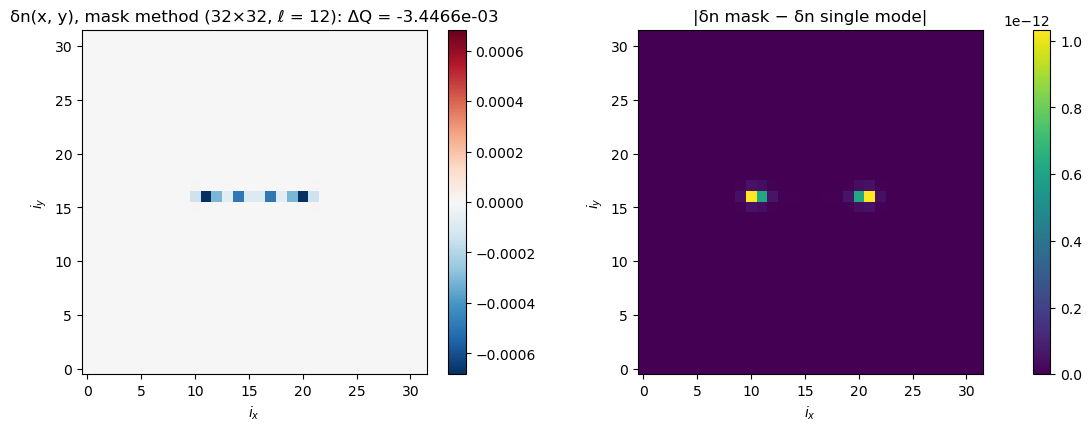

In [8]:
def mask_check(Lx, Ly, ell=12):
    "Charge difference of the fermion mode from the mask method (dense M) and from ⟨ψf|τz|ψf⟩, with δn on the lattice."
    H = ham(Lx, Ly, ell).toarray(); N = H.shape[0] // 4
    t_ = time.perf_counter(); E, M = la.eigh(H); t_eigh = time.perf_counter() - t_   # ascending energies
    # logical states as masks over the columns of M (as in msh_chain_python_ed.ipynb, section 7)
    masks = np.zeros((2, 4*N), bool)
    masks[1, 2*N] = True                                       # |1⟩: ψf (column 2N) filled; |0⟩: empty
    masks[:, :2*N] = np.flip(~masks[:, 2*N:], axis=1)          # partners: column 2N−1−k = C(column 2N+k)
    rho = np.empty((2, N))
    for j in range(2):
        A = M[:, masks[j]]
        rho[j] = (np.abs(A)**2).sum(1).reshape(N, 4)[:, :2].sum(1)   # particle diagonal of G = A A†, summed over spin
    dn_mask = rho[1] - rho[0]
    # single-mode formula from column 2N alone
    v = M[:, 2*N].reshape(N, 4)
    dn_single = (np.abs(v[:, :2])**2).sum(1) - (np.abs(v[:, 2:])**2).sum(1)
    Cpsi = (np.kron(sy, sy) @ v.conj().T).T.reshape(-1)       # C = τy σy K in kwant's basis
    overlap = abs(np.vdot(M[:, 2*N - 1], Cpsi))
    return dict(N=N, D=4*N, E_f=E[2*N], t_eigh=t_eigh, overlap=overlap, dQ_mask=dn_mask.sum(), dQ_single=dn_single.sum(),
                dn_err=np.abs(dn_mask - dn_single).max(), dn_mask=dn_mask.reshape(2**Ly, 2**Lx),
                dn_single=dn_single.reshape(2**Ly, 2**Lx))

mask_scan = [(6, 0), (6, 2), (4, 4), (5, 5)]
mc = {p: in_fresh_process(mask_check, *p)[0] for p in mask_scan}
print(f"{'substrate':>10s} {'D':>6s} {'E_f':>11s} {'|<M_2N-1|Cψf>|':>16s} {'ΔQ mask':>14s} {'ΔQ single':>14s} "
      f"{'|diff|':>8s} {'max|δn diff|':>13s} {'eigh':>6s}")
for (Lx, Ly), r in mc.items():
    print(f"{2**Lx:>5d}×{2**Ly:<4d} {r['D']:6d} {r['E_f']:11.4e} {r['overlap']:16.12f} {r['dQ_mask']:+14.10e} "
          f"{r['dQ_single']:+14.10e} {abs(r['dQ_mask'] - r['dQ_single']):8.1e} {r['dn_err']:13.1e} {r['t_eigh']:5.1f}s")

import matplotlib.pyplot as plt
r = mc[(5, 5)]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
vm = np.abs(r["dn_mask"]).max()
im = ax[0].imshow(r["dn_mask"], origin="lower", cmap="RdBu_r", vmin=-vm, vmax=vm)
ax[0].set_title(f"δn(x, y), mask method (32×32, ℓ = 12): ΔQ = {r['dQ_mask']:+.4e}")
fig.colorbar(im, ax=ax[0])
im = ax[1].imshow(np.abs(r["dn_mask"] - r["dn_single"]), origin="lower", cmap="viridis")
ax[1].set_title("|δn mask − δn single mode|")
fig.colorbar(im, ax=ax[1])
for a in ax:
    a.set_xlabel("$i_x$"); a.set_ylabel("$i_y$")
plt.show()

## 8. A substrate the zero modes leak into

At the benchmark point ($\mu = -7$, $\Delta = 2.4$, $J = 5.8$) the bare band ($\pm4.74$ with the Rashba term) is empty and $\Delta$ is large
compared with $t$, so the zero modes stay within about one row of the chain. This section looks for a topological point where they
spread into the substrate (a harder case for the tensor network), checks it, and gives the exact (MUMPS) reference for section 8 of
`msh_substrate_tn.ipynb`.

### 8a. μ × J scan for three values of Δ

$64\times32$ substrate, chain $\ell = 32$ in row 16, $\mu = -7 \dots 0$ (step 0.25), $J = 1 \dots 8$ (step 0.5), $\Delta = 2.4, 1.2, 0.6$:
1305 points, each by shift-invert `eigsh` (6 levels), on 8 processes (`RUN_MU = False` loads `py_mu_scan.csv`). Per point: the pair
splitting $E_0$, the next level $E_2$, and the spatial profile of the lowest state: its weight within 3 sites of the chain ends
(`w_ends`) and in the middle third of the chain (`w_mid`), on the chain row (`w_row`), 4 or more rows away (`w_far`), and its rms
distance from the chain row (`rms_dy`). A point counts as topological when $E_0/E_2 < 0.05$ and `w_ends` $> 0.5$. Top: $\log_{10}(E_0/E_2)$
with the topological region in red; bottom: `rms_dy` inside it; the dashed line is the band bottom.

1305 points in 198 s (8 processes)


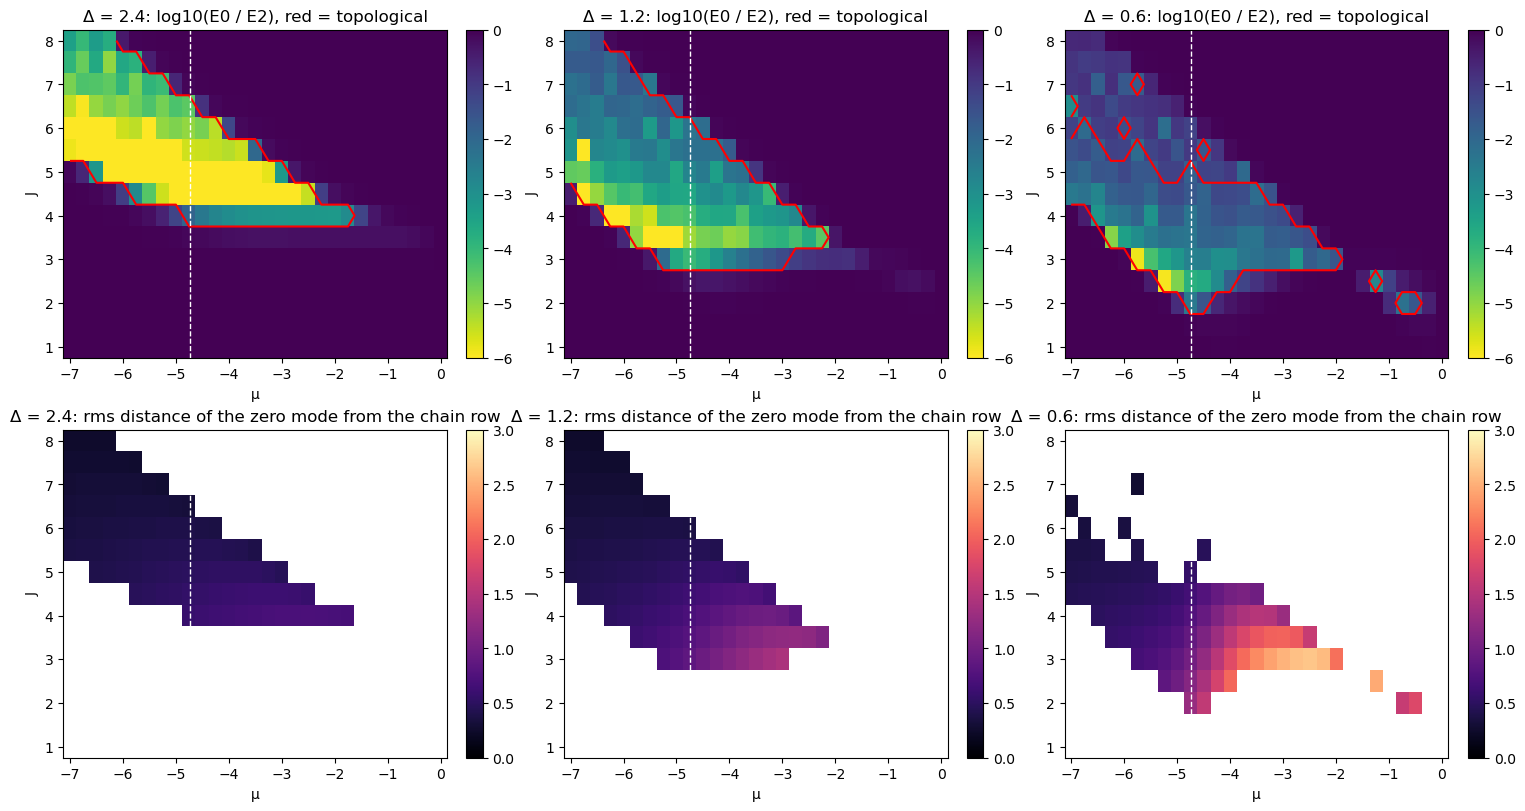

   Δ topological   largest gap E2 among topological points below / inside the band
 2.4          97   μ = -5.00, J = 5.0: E2 = 0.828, rms_dy = 0.48, w_far = 1.8e-04;  μ = -4.50, J = 5.0: E2 = 0.780, rms_dy = 0.51, w_far = 2.8e-04
 1.2         113   μ = -4.75, J = 3.5: E2 = 0.524, rms_dy = 0.79, w_far = 2.8e-03;  μ = -4.50, J = 4.0: E2 = 0.502, rms_dy = 0.77, w_far = 2.9e-03
 0.6          90   μ = -4.75, J = 3.0: E2 = 0.312, rms_dy = 1.02, w_far = 9.0e-03;  μ = -4.50, J = 3.0: E2 = 0.314, rms_dy = 1.24, w_far = 2.0e-02
Δ = 2.4, μ = -7.0, J = 6.0: E0/E2 = 6.3e-08, E2 = 0.634, w_row = 0.90, w_far = 1.6e-05, rms_dy = 0.35
Δ = 0.6, μ = -4.0, J = 3.0: E0/E2 = 1.1e-03, E2 = 0.237, w_row = 0.40, w_far = 6.3e-02, rms_dy = 1.82
Δ = 0.6, μ = -3.0, J = 3.0: E0/E2 = 8.2e-03, E2 = 0.097, w_row = 0.32, w_far = 1.3e-01, rms_dy = 2.53
Δ = 0.6, μ = -2.5, J = 3.0: E0/E2 = 1.8e-02, E2 = 0.065, w_row = 0.33, w_far = 1.4e-01, rms_dy = 2.64


In [9]:
from multiprocessing import Pool
RUN_MU = True
mu_file = "py_mu_scan.csv"
Lx_s, Ly_s, ell_s = 6, 5, 32
xs_s, iy0_s = chain_sites(Lx_s, Ly_s, ell_s)
ix_s, iy_s = np.meshgrid(np.arange(2**Lx_s), np.arange(2**Ly_s))
ends_s = (np.abs(ix_s - xs_s[0]) <= 3) | (np.abs(ix_s - xs_s[-1]) <= 3)
mid_s = (ix_s >= xs_s[0] + ell_s // 3) & (ix_s <= xs_s[-1] - ell_s // 3)
dy_s = np.abs(iy_s - iy0_s)

def scan_point(args):
    Delta, mu, J = args
    E, V = eigsh(ham(Lx_s, Ly_s, ell_s, mu=mu, Delta=Delta, J=J), k=6, sigma=0, which="LM")
    o = np.argsort(np.abs(E)); E = np.abs(E[o]); V = V[:, o]
    rho = (np.abs(V[:, 0].reshape(-1, 4))**2).sum(1).reshape(2**Ly_s, 2**Lx_s)
    return (Delta, mu, J, E[0], E[2], E[4], rho[ends_s].sum(), rho[mid_s].sum(), rho[iy0_s].sum(),
            np.sqrt((rho * dy_s**2).sum()), rho[dy_s >= 4].sum())

mu_cols = ["Delta", "mu", "J", "E0", "E2", "E4", "w_ends", "w_mid", "w_row", "rms_dy", "w_far"]
if RUN_MU or not os.path.isfile(mu_file):
    grid = [(D, mu, J) for D in (2.4, 1.2, 0.6) for mu in np.round(np.arange(-7.0, 0.01, 0.25), 2)
            for J in np.round(np.arange(1.0, 8.01, 0.5), 2)]
    t_ = time.perf_counter()
    with Pool(8) as pool:
        rows = pool.map(scan_point, grid, chunksize=4)
    with open(mu_file, "w") as fh:
        fh.write(",".join(mu_cols) + "\n")
        for r in rows:
            fh.write(",".join(str(x) for x in r) + "\n")
    print(f"{len(rows)} points in {time.perf_counter() - t_:.0f} s (8 processes)")
ms = np.genfromtxt(mu_file, delimiter=",", names=True)
topo = (ms["E0"] / ms["E2"] < 0.05) & (ms["w_ends"] > 0.5)

import matplotlib.pyplot as plt
Ds, mus, Js = sorted(set(ms["Delta"]), reverse=True), np.unique(ms["mu"]), np.unique(ms["J"])
fig, ax = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for j, D in enumerate(Ds):
    sel = ms["Delta"] == D
    def grid_of(vals):
        g = np.full((len(Js), len(mus)), np.nan)
        g[np.searchsorted(Js, ms["J"][sel]), np.searchsorted(mus, ms["mu"][sel])] = vals
        return g
    ext = [mus[0] - 0.125, mus[-1] + 0.125, Js[0] - 0.25, Js[-1] + 0.25]
    im = ax[0, j].imshow(grid_of(np.log10(ms["E0"][sel] / ms["E2"][sel])), origin="lower", aspect="auto", extent=ext,
                         cmap="viridis_r", vmin=-6, vmax=0)
    ax[0, j].contour(mus, Js, grid_of(topo[sel].astype(float)), levels=[0.5], colors="r")
    ax[0, j].set_title(f"Δ = {D}: log10(E0 / E2), red = topological"); fig.colorbar(im, ax=ax[0, j])
    im = ax[1, j].imshow(grid_of(np.where(topo[sel], ms["rms_dy"][sel], np.nan)), origin="lower", aspect="auto", extent=ext,
                         cmap="magma", vmin=0, vmax=3)
    ax[1, j].set_title(f"Δ = {D}: rms distance of the zero mode from the chain row"); fig.colorbar(im, ax=ax[1, j])
    for a in ax[:, j]:
        a.axvline(-4.741, color="w", ls="--", lw=1); a.set_xlabel("μ"); a.set_ylabel("J")
plt.show()

print(f"{'Δ':>4s} {'topological':>11s}   largest gap E2 among topological points below / inside the band")
for D in Ds:
    s_ = (ms["Delta"] == D) & topo
    best = [ms[s_ & cond][np.argmax(ms[s_ & cond]["E2"])] for cond in (ms["mu"] <= -4.74, ms["mu"] > -4.74) if (s_ & cond).any()]
    print(f"{D:4.1f} {s_.sum():11d}   " + ";  ".join(f"μ = {r['mu']:.2f}, J = {r['J']:.1f}: E2 = {r['E2']:.3f}, rms_dy = {r['rms_dy']:.2f}, "
                                                    f"w_far = {r['w_far']:.1e}" for r in best))
for D, mu, J in ((2.4, -7.0, 6.0), (0.6, -4.0, 3.0), (0.6, -3.0, 3.0), (0.6, -2.5, 3.0)):
    r = ms[(ms["Delta"] == D) & (ms["mu"] == mu) & (ms["J"] == J)][0]
    print(f"Δ = {D}, μ = {mu}, J = {J}: E0/E2 = {r['E0'] / r['E2']:.1e}, E2 = {r['E2']:.3f}, w_row = {r['w_row']:.2f}, "
          f"w_far = {r['w_far']:.1e}, rms_dy = {r['rms_dy']:.2f}")

### 8b. The point Δ = 0.6, μ = −3, J = 3: chain length, substrate height, decay into the substrate

Inside the band, gapped, and with the largest spread among the topological points with a gap near 0.1. Three checks with shift-invert
`eigsh` (spins along $\hat z$): the pair splitting against the chain length on a $256\times32$ substrate; the convergence of $E_0$, the gap and
$\Delta Q$ with the substrate height ($N_x = 256$, $\ell = 64$); and the weight of the fermion mode per row against the distance from
the chain row ($256\times128$, $\ell = 64$).

In [10]:
PC = dict(mu=-3.0, Delta=0.6, J=3.0)

def pair_levels(Lx, Ly, ell):
    E, V = eigsh(ham(Lx, Ly, ell, **PC), k=6, sigma=0, which="LM")
    o = np.argsort(np.abs(E)); E, V = E[o], V[:, o]
    ip = np.argmax(E[:2]); v = V[:, ip].reshape(-1, 4)
    dQ = np.sum(np.abs(v[:, :2])**2) - np.sum(np.abs(v[:, 2:])**2)
    return abs(E[0]), abs(E[2]), dQ, (np.abs(v)**2).sum(1).reshape(2**Ly, 2**Lx)

print("pair splitting against chain length (256 × 32)")
print(f"{'ℓ':>4s} {'E0':>10s} {'E2':>8s} {'E0/E2':>9s} {'ΔQ':>11s}")
for ell in (16, 24, 32, 48, 64, 80, 96, 128):
    E0, E2, dQ, _ = in_fresh_process(pair_levels, 8, 5, ell)[0]
    print(f"{ell:4d} {E0:10.3e} {E2:8.4f} {E0 / E2:9.1e} {dQ:+11.3e}")

print("\nsubstrate height (N_x = 256, ℓ = 64)")
for Ly in (3, 4, 5, 6, 7):
    E0, E2, dQ, _ = in_fresh_process(pair_levels, 8, Ly, 64)[0]
    print(f"N_y = {2**Ly:4d}: E0 = {E0:.6e}, E2 = {E2:.6f}, ΔQ = {dQ:+.6e}")

E0, E2, dQ, rho = in_fresh_process(pair_levels, 8, 7, 64)[0]
row, iy0 = rho.sum(1), 2**7 // 2
print("\nweight of the fermion mode per row against the distance from the chain row (256 × 128, ℓ = 64)")
print("  ".join(f"Δy = {d}: {0.5 * (row[iy0 + d] + row[iy0 - d]):.1e}" for d in (0, 1, 2, 4, 8, 16, 24, 32, 48)))

pair splitting against chain length (256 × 32)
   ℓ         E0       E2     E0/E2          ΔQ
  16  5.835e-03   0.1225   4.8e-02  -5.339e-02
  24  3.355e-04   0.1036   3.2e-03  +3.324e-02
  32  7.934e-04   0.0966   8.2e-03  +1.025e-02
  48  1.034e-04   0.0918   1.1e-03  -2.080e-03
  64  9.044e-06   0.0902   1.0e-04  +4.582e-04
  80  2.129e-06   0.0895   2.4e-05  -3.313e-05
  96  5.758e-08   0.0891   6.5e-07  +1.319e-05
 128  7.128e-10   0.0887   8.0e-09  -2.989e-07

substrate height (N_x = 256, ℓ = 64)
N_y =    8: E0 = 1.066821e-05, E2 = 0.115036, ΔQ = +5.535520e-04
N_y =   16: E0 = 8.742310e-06, E2 = 0.085210, ΔQ = +4.406702e-04
N_y =   32: E0 = 9.043719e-06, E2 = 0.090208, ΔQ = +4.581532e-04
N_y =   64: E0 = 9.047712e-06, E2 = 0.090249, ΔQ = +4.583431e-04
N_y =  128: E0 = 9.047709e-06, E2 = 0.090248, ΔQ = +4.583435e-04

weight of the fermion mode per row against the distance from the chain row (256 × 128, ℓ = 64)
Δy = 0: 3.2e-01  Δy = 1: 1.5e-01  Δy = 2: 8.1e-02  Δy = 4: 2.6e-02  Δy 

### 8c. MUMPS reference at the TN sizes

MUMPS (METIS) shift-invert for $\ell = 64$ on the sizes of section 8 of `msh_substrate_tn.ipynb` up to $1024\times1024$, each in a forked
process (time of the eigensolver and peak memory, as in section 5; `py_candidate.csv`, resumable like section 5). The factorization
depends only on the sparsity pattern, so the size and flop estimates of section 6 hold here too; at $2048\times2048$ the time is
estimated from the measured $1024\times1024$ time and the ratio of the estimated flops.

In [11]:
cand_file = "py_candidate.csv"
cand_scan = [(7, 6), (8, 8), (9, 9), (10, 10)]
cand_cols = ["Lx", "Ly", "ell", "N", "t", "rss_MB", "E_f", "dQ", "E_gap", "status"]

def solve_candidate(Lx, Ly, ell=64):
    H = ham(Lx, Ly, ell, **PC)
    t_ = time.perf_counter()
    ctx = mumps.Context(); ctx.factor(H.tocoo(), ordering="metis")
    E, V = eigsh(H, k=4, sigma=0, which="LM", OPinv=LinearOperator(H.shape, matvec=ctx.solve, dtype=complex))
    return (time.perf_counter() - t_, *pair_values(E, V))

done = set()
if os.path.isfile(cand_file):
    done = {(int(r["Lx"]), int(r["Ly"])) for r in np.genfromtxt(cand_file, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)}
else:
    with open(cand_file, "w") as fh:
        fh.write(",".join(cand_cols) + "\n")
for Lx, Ly in cand_scan:
    if (Lx, Ly) in done:
        continue
    out, rss, status = in_fresh_process(solve_candidate, Lx, Ly)
    t, Ef, dQ, gap = out if out is not None else (np.nan,) * 4
    with open(cand_file, "a") as fh:
        fh.write(",".join(str(x) for x in (Lx, Ly, 64, 2**(Lx + Ly), t, rss, Ef, dQ, gap, status)) + "\n")

pc = np.genfromtxt(cand_file, delimiter=",", names=True, dtype=None, encoding=None, ndmin=1)
est = {(int(r["Lx"]), int(r["Ly"])): r for r in np.genfromtxt("py_mumps_estimates.csv", delimiter=",", names=True)}
print(f"{'substrate':>11s} {'N':>8s} {'MUMPS':>9s} {'RSS MB':>9s} {'E_f':>13s} {'ΔQ':>13s} {'gap':>9s}  status")
for r in pc:
    print(f"{2**r['Lx']:>5d}×{2**r['Ly']:<5d} {r['N']:8d} {r['t']:8.1f}s {r['rss_MB']:9.0f} {r['E_f']:13.6e} {r['dQ']:+13.6e} "
          f"{r['E_gap']:9.6f}  {r['status']}")
t1024 = pc[(pc["Lx"] == 10) & (pc["Ly"] == 10)]["t"][0]
print(f"{2048:>5d}×{2048:<5d} {4**11:8d} {'~' + format(t1024 * est[(11, 11)]['est_flops'] / est[(10, 10)]['est_flops'], '.0f'):>8s}s "
      f"{'~' + format(est[(11, 11)]['est_mem_incore_MB'], '.0f'):>9s}   (estimate)")

  substrate        N     MUMPS    RSS MB           E_f            ΔQ       gap  status
  128×64        8192      1.0s       318  9.047711e-06 +4.583432e-04  0.090249  ok
  256×256      65536     10.7s      1603  9.047709e-06 +4.583435e-04  0.090248  ok
  512×512     262144     53.7s      6638  9.047709e-06 +4.583435e-04  0.090248  ok
 1024×1024   1048576    295.1s     28625  9.047709e-06 +4.583435e-04  0.090248  ok
 2048×2048   4194304    ~2326s   ~121184   (estimate)
